In [1]:
!pip install palmerpenguins

In [1]:
import numpy as np
import pandas as pd
from sys import exit
from palmerpenguins import load_penguins
from plotnine import ggplot, aes, geom_point, geom_bar

0\. Complete the [**check-in** from Section 6.3.2](https://ds-ml-with-python.github.io/Course-Textbook/05-function_writing.html#nested-environments-and-scope): Write a custom function that does the following:

Limit the penguins dataset to a user-chosen species and/or island.
Makes a scatterplot of the penguin bill length and depth.
Try writing a version of this function using dynamic lookup, and a version where everything the function needs is passed in directly

/opt/anaconda3/lib/python3.14/site-packages/plotnine/layer.py:374: PlotnineWarning: geom_point : Removed 1 rows containing missing values.


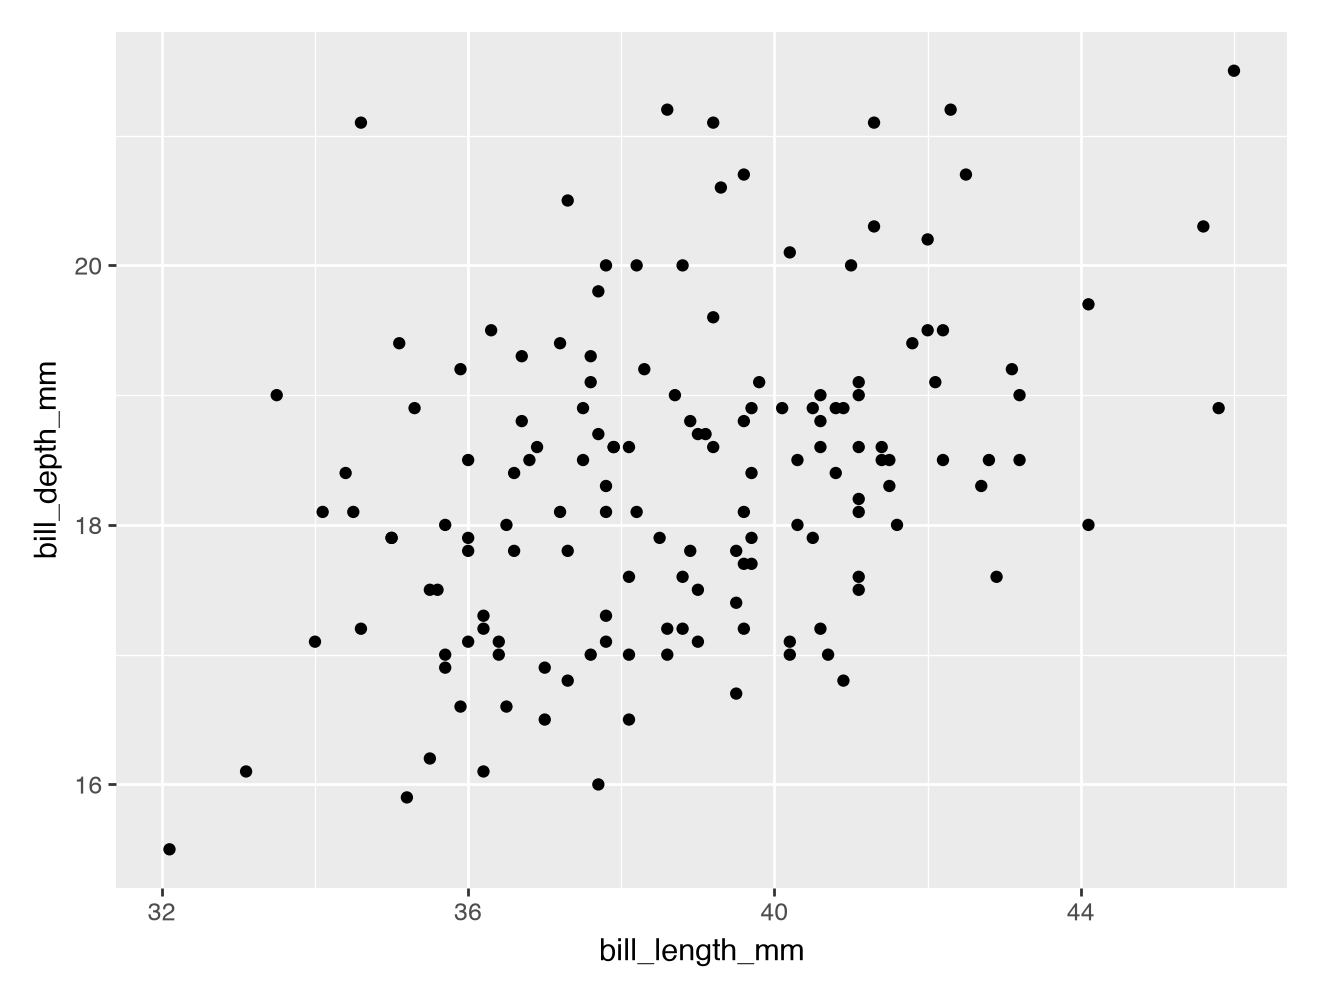

In [ ]:
penguins = load_penguins()

# Version 1: dynamic lookup
def plot_bill_dynamic(species=None, island=None):
    df = penguins.copy()
    if species is not None:
        df = df[df["species"] == species]
    if island is not None:
        df = df[df["island"] == island]
    return ggplot(df, aes(x="bill_length_mm", y="bill_depth_mm")) + geom_point()

plot_bill_dynamic(species="Adelie")

/opt/anaconda3/lib/python3.14/site-packages/plotnine/layer.py:374: PlotnineWarning: geom_point : Removed 1 rows containing missing values.


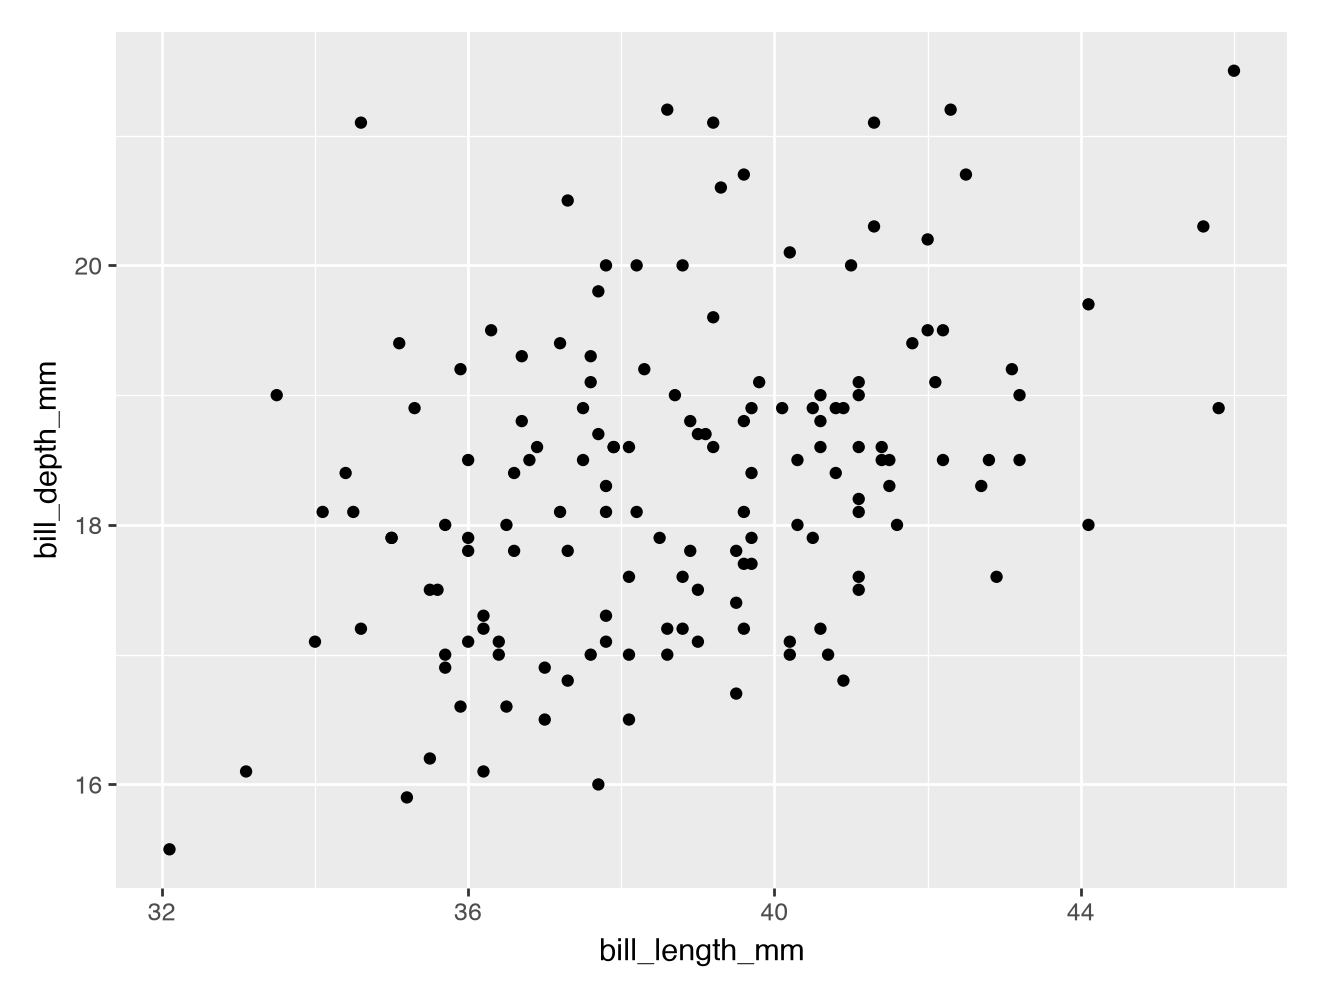

In [ ]:
# Version 2:
def plot_bill_explicit(data, species=None, island=None):
    df = data.copy()
    if species is not None:
        df = df[df["species"] == species]
    if island is not None:
        df = df[df["island"] == island]
    return ggplot(df, aes(x="bill_length_mm", y="bill_depth_mm")) + geom_point()

plot_bill_explicit(penguins, species="Adelie")

1. Fill in the necessary code to write a function called `times_seven()`. The function should take a single argument (`x`) and multiply the input by 7.
  + This function should check that the argument is numeric.
  + This function should also excitedly announce (print) *“I love sevens!”* if the argument to the function is a 7.

In [4]:
def times_seven(x):
    if not isinstance(x, (int, float)):
        exit("x must be numeric")

    if x == 7:
        print("I love sevens!")

    return x * 7

2. Write and run some *unit tests* for your `times_seven` function.  What happens if the input to the function is `[1, 3, 5, 7]`?

In [5]:
print(times_seven(3))              # 21
print(times_seven(7))              # prints "I love sevens!" then returns 49
print(times_seven([1, 3, 5, 7]))   # a list fails the isinstance check

21
I love sevens!
49


SystemExit: x must be numeric

When the function is `[1, 3, 5, 7]`, the list fails the numeric check, so the function calls exit and stops returning a value. 

3. Consider the following function:

In [6]:
def add_or_subtract(first_num, second_num = 2, type = "add"):

  if (type == "add"):
    res = first_num + second_num
  elif (type == "subtract"):
    res = first_num - second_num
  else:
    exit("Please choose `add` or `subtract` as the type.")

    return res

**Without running the code**, predict if the following will produce:

a. 1

b. -1

c. 30

d. An error defined by the function `add_or_subtract()`

e. An error defined in a different function, which is called inside the `add_or_subtract()` function

I predict that it will produce d). The second call (add_or_subtract("orange")) raises a TypeError directly inside the function's own code which stops it before reaching the third call. 

In [7]:
add_or_subtract(5, 6, type = "subtract")

add_or_subtract("orange")

add_or_subtract(5, 6, type = "multiply")

TypeError: can only concatenate str (not "int") to str

4. Consider the following code:

In [8]:
first_num  = 5
second_num = 3

result = 8

result = add_or_subtract(first_num, second_num = 4)

result_2 = add_or_subtract(first_num)


In your Global Environment, what is the value of...

a. `first_num`

b. `second_num`

c. `result`

d. `result_2`

a. first_num = 5

b. second_num = 3 

c. result = None 

d. result_2 = None
